# 1.)**Importing Dependencies**

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai'):
    print(dirname)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/train


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.models as models


from PIL import Image
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from torch.utils.data import Dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

In [3]:
DATA_DIR='/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai'

In [4]:
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

print("\nFirst 5 training files:")
print(os.listdir(TRAIN_DIR)[:5])


TRAIN_DIR: /kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/train
TEST_DIR: /kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test

First 5 training files:
['train_03637.jpg', 'train_04409.jpg', 'train_00232.jpg', 'train_02167.jpg', 'train_06889.jpg']


In [5]:
train_df=pd.read_csv('/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/train.csv')
test_df=pd.read_csv('/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test.csv')
classes_df=pd.read_csv('/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/classes.csv')

In [6]:
print("="*63)
print("1.)Overview of Classes : ")
print("-"*63)
print(classes_df.head(20))
print("="*63)
print("2.)Training Images Data : ")
print("-"*63)
print(train_df.head(10))

1.)Overview of Classes : 
---------------------------------------------------------------
    label                class_name        material  condition
0       0              glass_defect           glass     defect
1       1           glass_no_defect           glass  no_defect
2       2             rubber_defect          rubber     defect
3       3          rubber_no_defect          rubber  no_defect
4       4       hard_plastic_defect    hard_plastic     defect
5       5    hard_plastic_no_defect    hard_plastic  no_defect
6       6        wood_coated_defect     wood_coated     defect
7       7     wood_coated_no_defect     wood_coated  no_defect
8       8      wood_uncoated_defect   wood_uncoated     defect
9       9   wood_uncoated_no_defect   wood_uncoated  no_defect
10     10              cable_defect           cable     defect
11     11           cable_no_defect           cable  no_defect
12     12          cardboard_defect       cardboard     defect
13     13       cardboard_no

In [7]:
def idnum(l):
    label_number=l
    return train_df[train_df["label"]==label_number]["id"].values
for i in range(20):
     print(f' Images for {i} Label : {len(idnum(i))}')

 Images for 0 Label : 499
 Images for 1 Label : 456
 Images for 2 Label : 550
 Images for 3 Label : 467
 Images for 4 Label : 609
 Images for 5 Label : 420
 Images for 6 Label : 538
 Images for 7 Label : 474
 Images for 8 Label : 621
 Images for 9 Label : 442
 Images for 10 Label : 495
 Images for 11 Label : 532
 Images for 12 Label : 550
 Images for 13 Label : 519
 Images for 14 Label : 455
 Images for 15 Label : 385
 Images for 16 Label : 486
 Images for 17 Label : 437
 Images for 18 Label : 484
 Images for 19 Label : 489


# 2.)**Baseline Model**

In [8]:
class MaterialDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        image_id = self.dataframe.loc[index, "id"]
        label = self.dataframe.loc[index, "label"]

        image_path = os.path.join(self.image_dir, f"{image_id}.jpg")

        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [9]:
# Create a temporary dataset instance without transformations
test_dataset = MaterialDataset(
    dataframe=train_df,
    image_dir=TRAIN_DIR,
    transform=None
)

print("Dataset length:", len(test_dataset))

# Retrieve the first sample
image, label = test_dataset[0]

print("Image type:", type(image))
print("Label:", label)
print("Label type:", type(label))
print("Image size:", image.size)

Dataset length: 9908
Image type: <class 'PIL.Image.Image'>
Label: tensor(1)
Label type: <class 'torch.Tensor'>
Image size: (224, 224)


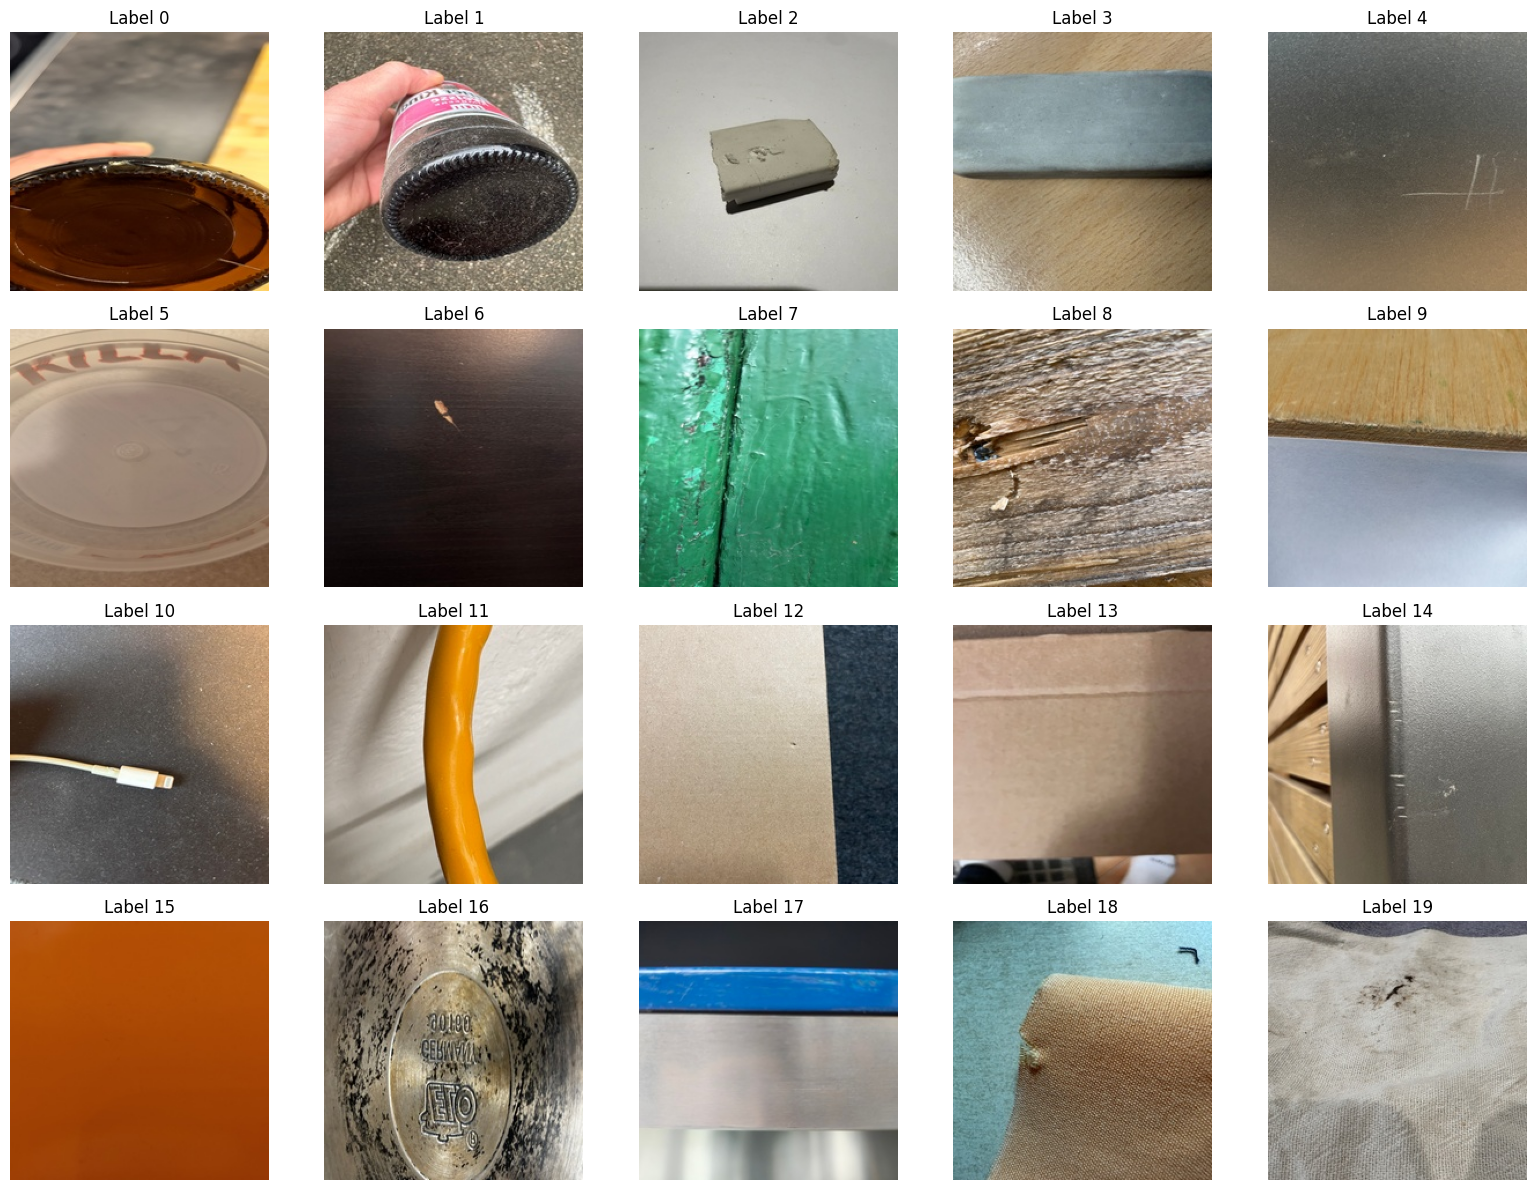

In [10]:
fig, axes = plt.subplots(4, 5, figsize=(16, 12))

for label in range(20):

    # Select the first image belonging to this label
    sample = train_df[train_df["label"] == label].iloc[0]

    # Construct the image path
    image_path = os.path.join(TRAIN_DIR, f"{sample['id']}.jpg")

    # Load the image
    image = Image.open(image_path).convert("RGB")

    # Find its position in the grid
    ax = axes[label // 5, label % 5]

    # Display the image
    ax.imshow(image)
    ax.set_title(f"Label {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 3.)Train Test Split

In [11]:
train_split, val_split = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["label"]
)

train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))

Training samples: 7926
Validation samples: 1982


# 4.)Data Transformation and Augmentation

In [12]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [13]:
train_dataset = MaterialDataset(
    dataframe=train_split,
    image_dir=TRAIN_DIR,
    transform=train_transform
)

val_dataset = MaterialDataset(
    dataframe=val_split,
    image_dir=TRAIN_DIR,
    transform=val_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Train dataset: 7926
Validation dataset: 1982


In [14]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 248
Validation batches: 62


In [15]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Min pixel value:", images.min().item())
print("Max pixel value:", images.max().item())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Min pixel value: 0.0
Max pixel value: 1.0


In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [17]:
print("GPU:", torch.cuda.get_device_name(0))
print("GPU available:", torch.cuda.is_available())
print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

GPU: Tesla T4
GPU available: True
GPU memory: 14.56 GB


In [18]:
model = torchvision.models.resnet18(weights=None)

model.fc = nn.Linear(model.fc.in_features, 20)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)
print("Model created successfully!")
print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Model created successfully!
Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Initial learning rate: 0.001


# 5.)Training Loop

In [19]:
# EPOCHS = 15

# best_val_f1 = 0.0

# MODEL_PATH = "/kaggle/working/best_resnet18_baseline.pth"

# def train_one_epoch(model, train_loader, criterion, optimizer, device):

#     model.train()

#     running_loss = 0.0
#     all_preds = []
#     all_labels = []

#     for images, labels in train_loader:

#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer.zero_grad()

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item()

#         predictions = outputs.argmax(dim=1)

#         all_preds.extend(predictions.cpu().numpy())
#         all_labels.extend(labels.cpu().numpy())

#     epoch_loss = running_loss / len(train_loader)
#     epoch_f1 = f1_score(all_labels, all_preds, average="macro")
#     epoch_acc = accuracy_score(all_labels, all_preds)

#     return epoch_loss, epoch_acc, epoch_f1

In [20]:
# def validate_one_epoch(model, val_loader, criterion, device):

#     model.eval()

#     running_loss = 0.0
#     all_preds = []
#     all_labels = []

#     with torch.no_grad():

#         for images, labels in val_loader:

#             images = images.to(device)
#             labels = labels.to(device)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             running_loss += loss.item()

#             predictions = outputs.argmax(dim=1)

#             all_preds.extend(predictions.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     epoch_loss = running_loss / len(val_loader)
#     epoch_f1 = f1_score(all_labels, all_preds, average="macro")
#     epoch_acc = accuracy_score(all_labels, all_preds)

#     return epoch_loss, epoch_acc, epoch_f1

In [21]:
# for epoch in range(EPOCHS):

#     train_loss, train_acc, train_f1 = train_one_epoch(
#         model, train_loader, criterion, optimizer, device
#     )

#     val_loss, val_acc, val_f1 = validate_one_epoch(
#         model, val_loader, criterion, device
#     )

#     print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
#     print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_f1:.4f}")
#     print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val F1:   {val_f1:.4f}")

#     if val_f1 > best_val_f1:

#         best_val_f1 = val_f1

#         torch.save(model.state_dict(), MODEL_PATH)

#         print(f"New best model saved! Val Macro-F1: {best_val_f1:.4f}")

In [22]:
# model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
# model.to(device)
# model.eval()

# print("Best model checkpoint loaded successfully!")

In [23]:
# class TestDataset(Dataset):

#     def __init__(self, dataframe, image_dir, transform=None):
#         self.dataframe = dataframe.reset_index(drop=True)
#         self.image_dir = image_dir
#         self.transform = transform

#     def __len__(self):
#         return len(self.dataframe)

#     def __getitem__(self, index):

#         image_id = self.dataframe.loc[index, "id"]

#         image_path = os.path.join(self.image_dir, f"{image_id}.jpg")

#         image = Image.open(image_path).convert("RGB")

#         if self.transform is not None:
#             image = self.transform(image)

#         return image, image_id

In [24]:
# test_dataset = TestDataset(
#     dataframe=test_df,
#     image_dir=TEST_DIR,
#     transform=val_transform
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=2,
#     pin_memory=True
# )

# print("Test images:", len(test_dataset))
# print("Test batches:", len(test_loader))

In [25]:
# model.eval()

# test_predictions = []
# test_ids = []

# with torch.no_grad():

#     for images, image_ids in test_loader:

#         images = images.to(device)

#         outputs = model(images)

#         predictions = outputs.argmax(dim=1)

#         test_predictions.extend(predictions.cpu().numpy())
#         test_ids.extend(image_ids)

# print("Total predictions:", len(test_predictions))
# print("Total IDs:", len(test_ids))
# print("First 10 predictions:", test_predictions[:10])

In [26]:
# submission = pd.DataFrame({
#     "id": test_ids,
#     "label": test_predictions
# })

# submission.to_csv("/kaggle/working/submission.csv", index=False)

# print(submission.head(10))
# print("\nSubmission shape:", submission.shape)



# Kaggle Score for Resnet_18 : **0.24749 V1**

In [27]:
# Experiment 3: ResNet34 - Optimized

# model = torchvision.models.resnet34(weights=None)

# model.fc = nn.Linear(model.fc.in_features, 20)

# model = model.to(device)

# EPOCHS = 40
# best_val_f1 = 0.0

# MODEL_PATH = "/kaggle/working/best_resnet34_exp3.pth"

# criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=0.0005,
#     weight_decay=0.0001
# )

# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer,
#     T_max=EPOCHS,
#     eta_min=1e-6
# )

# print("Experiment 3 initialized")
# print("Architecture: ResNet34")
# print("Epochs:", EPOCHS)
# print("Device:", device)
# print("Parameters:", sum(p.numel() for p in model.parameters()))

In [28]:
def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    return epoch_loss, epoch_f1, epoch_acc

In [29]:
# # Experiment 3: ResNet34

# model = torchvision.models.resnet34(weights=None)

# model.fc = nn.Linear(model.fc.in_features, 20)

# model = model.to(device)

# # Loss function
# criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# # Optimizer
# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=0.0005,
#     weight_decay=0.0001
# )

# # Settings
# EPOCHS = 45
# best_val_f1 = 0.0

# MODEL_PATH = "/kaggle/working/best_resnet34_exp3.pth"

# # Scheduler
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer,
#     T_max=EPOCHS,
#     eta_min=1e-6
# )

# print("Experiment 3 initialized successfully")
# print("Architecture: ResNet34")
# print("Epochs:", EPOCHS)
# print("Device:", device)
# print("Optimizer connected to fresh model")
# print("Scheduler:", scheduler)

In [30]:
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds, average="macro")
    epoch_acc = accuracy_score(all_labels, all_preds)

    return epoch_loss, epoch_f1, epoch_acc

In [31]:
# for epoch in range(EPOCHS):

#     # Training
#     train_loss, train_f1, train_acc = train_one_epoch(
#         model, train_loader, optimizer, criterion, device
#     )

    # # Validation
    # val_loss, val_f1, val_acc = validate_one_epoch(
    #     model, val_loader, criterion, device
    # )

    # # Learning rate scheduler
    # scheduler.step()

    # current_lr = optimizer.param_groups[0]["lr"]

    # # Save best model
    # if val_f1 > best_val_f1:
    #     best_val_f1 = val_f1

    #     torch.save(model.state_dict(), MODEL_PATH)

    #     print("Best model saved!")

    # # Epoch results
    # print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    # print(f"Train Loss: {train_loss:.4f} | Train F1: {train_f1:.4f} | Train Acc: {train_acc:.4f}")
    # print(f"Val Loss:   {val_loss:.4f} | Val F1:   {val_f1:.4f} | Val Acc:   {val_acc:.4f}")
    # print(f"Learning Rate: {current_lr:.6f}")
    # print(f"Best Val F1: {best_val_f1:.4f}")
    # print("-" * 60)

In [32]:
#Load best Experiment 3 model (ResNet34)

# model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
# model.eval()

# print("Best Exp-3 checkpoint loaded successfully")
# print("Best validation Macro-F1:", best_val_f1)

In [33]:
# Experiment 2: Test Dataset

# class TestDataset(Dataset):

#     def __init__(self, dataframe, image_dir, transform=None):
#         self.df = dataframe.reset_index(drop=True)
#         self.image_dir = image_dir
#         self.transform = transform

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         img_id = self.df.iloc[idx]["id"]

#         img_path = os.path.join(
#             self.image_dir,
#             f"{img_id}.jpg"
#         )

#         image = Image.open(img_path).convert("RGB")

#         if self.transform:
#             image = self.transform(image)

#         return image, img_id

In [34]:
# test_dataset = TestDataset(
#     test_df,
#     TEST_DIR,
#     transform=val_transform
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=2
# )

# print("Test dataset size:", len(test_dataset))
# print("Test batches:", len(test_loader))

In [35]:
# Experiment 4: Test-Time Augmentation (Horizontal Flip)

# model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
# model.eval()

# predictions = []
# test_ids = []

# with torch.no_grad():
#     for images, ids in test_loader:
#         images = images.to(device)

#         # Original predictions
#         outputs_original = model(images)

#         # Horizontally flipped predictions
#         flipped_images = torch.flip(images, dims=[3])
#         outputs_flipped = model(flipped_images)

#         # Average logits
#         outputs = (outputs_original + outputs_flipped) / 2

#         preds = torch.argmax(outputs, dim=1).cpu().numpy()

#         predictions.extend(preds)
#         test_ids.extend(ids)

# print("Total predictions:", len(predictions))
# print("Total IDs:", len(test_ids))

In [36]:
# submission = pd.DataFrame({
#     "id": test_ids,
#     "label": predictions
# })

# submission.to_csv(
#     "/kaggle/working/submission.csv",
#     index=False
# )

# print(submission.head(10))
# print("\nSubmission shape:", submission.shape)

In [37]:
# GoogLeNet - Experiment 4
# model = models.googlenet(
#     weights=None,
#     aux_logits=True
# )

# # Main classifier: 1000 -> 20 classes
# model.fc = nn.Linear(model.fc.in_features, 20)

# # Auxiliary classifiers: 1000 -> 20 classes
# model.aux1.fc2 = nn.Linear(model.aux1.fc2.in_features, 20)
# model.aux2.fc2 = nn.Linear(model.aux2.fc2.in_features, 20)

# model = model.to(device)

# criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=0.0005,
#     weight_decay=0.0001
# )

# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer,
#     T_max=20
# )

# print("GoogLeNet initialized successfully!")
# print(f"Number of classes: {20}")
# print(f"Device: {device}")

In [38]:
# def train_googlenet_one_epoch(model, loader, optimizer, criterion, device):
#     model.train()

#     running_loss = 0.0
#     all_preds = []
#     all_labels = []

#     for images, labels in loader:
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer.zero_grad()

#         outputs = model(images)

#         # GoogLeNet returns main output + auxiliary outputs during training
#         main_logits = outputs.logits
#         aux2_logits = outputs.aux_logits2
#         aux1_logits = outputs.aux_logits1

    #     # Combined loss
    #     loss_main = criterion(main_logits, labels)
    #     loss_aux1 = criterion(aux1_logits, labels)
    #     loss_aux2 = criterion(aux2_logits, labels)

    #     loss = loss_main + 0.3 * loss_aux1 + 0.3 * loss_aux2

    #     loss.backward()
    #     optimizer.step()

    #     running_loss += loss.item() * images.size(0)

    #     preds = main_logits.argmax(dim=1)
    #     all_preds.extend(preds.detach().cpu().numpy())
    #     all_labels.extend(labels.detach().cpu().numpy())

    # epoch_loss = running_loss / len(loader.dataset)

    # epoch_f1 = f1_score(
    #     all_labels,
    #     all_preds,
    #     average="macro"
    # )

    # return epoch_loss, epoch_f1

In [39]:
# model.train()

# images, labels = next(iter(train_loader))
# images = images.to(device)
# labels = labels.to(device)

# with torch.no_grad():
#     outputs = model(images)

# print("Main output:", outputs.logits.shape)
# print("Auxiliary 1:", outputs.aux_logits1.shape)
# print("Auxiliary 2:", outputs.aux_logits2.shape)

# loss = (
#     criterion(outputs.logits, labels)
#     + 0.3 * criterion(outputs.aux_logits1, labels)
#     + 0.3 * criterion(outputs.aux_logits2, labels)
# )

# print("Combined loss:", loss.item())
# print("Batch size:", images.shape[0])

# model.train()

In [40]:
# NUM_EPOCHS = 30
# best_googlenet_f1 = 0.0

# history_googlenet = []

# for epoch in range(NUM_EPOCHS):

#     train_loss, train_f1 = train_googlenet_one_epoch(
#         model, train_loader, optimizer, criterion, device
#     )

#     val_loss, val_f1, val_acc = validate_one_epoch(
#         model, val_loader, criterion, device
#     )

#     scheduler.step()

#     history_googlenet.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "train_f1": train_f1,
#         "val_loss": val_loss,
#         "val_f1": val_f1,
#         "val_acc": val_acc
#     })

#     print(
#         f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
#         f"Train Loss: {train_loss:.4f} | "
#         f"Train F1: {train_f1:.4f} | "
#         f"Val Loss: {val_loss:.4f} | "
#         f"Val F1: {val_f1:.4f} | "
#         f"Val Acc: {val_acc:.4f}"
#     )

#     # Save epoch checkpoint
#     torch.save(
#         model.state_dict(),
#         f"/kaggle/working/googlenet_epoch_{epoch+1}.pth"
#     )

#     # Save best checkpoint based on validation Macro-F1
#     if val_f1 > best_googlenet_f1:
#         best_googlenet_f1 = val_f1

#         torch.save(
#             model.state_dict(),
#             "/kaggle/working/best_googlenet.pth"
#         )

#         print(f"  --> New best GoogLeNet! Val F1: {best_googlenet_f1:.4f}")

# print(f"\nBest GoogLeNet Validation Macro-F1: {best_googlenet_f1:.4f}")

In [41]:
# # Load the best GoogLeNet checkpoint
# model.load_state_dict(
#     torch.load(
#         "/kaggle/working/best_googlenet.pth",
#         map_location=device
#     )
# )

# model.eval()

# print("Best GoogLeNet checkpoint loaded successfully!")

In [42]:
# model.eval()

# all_predictions = []

# with torch.no_grad():
#     for images, image_ids in test_loader:
#         images = images.to(device)

#         # Original prediction
#         outputs1 = model(images)
#         probs1 = torch.softmax(outputs1, dim=1)

#         # Horizontal flip prediction
#         flipped_images = torch.flip(images, dims=[3])
#         outputs2 = model(flipped_images)
#         probs2 = torch.softmax(outputs2, dim=1)

#         # Average probabilities
#         avg_probs = (probs1 + probs2) / 2

#         preds = avg_probs.argmax(dim=1)
#         all_predictions.extend(preds.cpu().numpy())

# print("Total predictions:", len(all_predictions))
# print("Unique predicted classes:", len(set(all_predictions)))

In [43]:
class TestDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = self.df.iloc[idx]["id"]

        img_path = os.path.join(
            self.image_dir,
            f"{img_id}.jpg"
        )

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, img_id

test_dataset = TestDataset(
    test_df,
    TEST_DIR,
    transform=val_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Test dataset size:", len(test_dataset))
print("Test batches:", len(test_loader))

Test dataset size: 3325
Test batches: 104


In [44]:
# test_ids = test_df["id"].tolist()

# submission = pd.DataFrame({
#     "id": test_ids,
#     "label": all_predictions
# })

# submission.to_csv(
#     "/kaggle/working/submission.csv",
#     index=False
# )

# print(submission.head(10))
# print("\nSubmission shape:", submission.shape)

In [45]:
# Experiment 5: DenseNet121 (Training from Scratch)

# import torch
# import torch.nn as nn
# import torchvision.models as models

# model = models.densenet121(weights=None)

# # Replace the classifier for our 20 classes
# model.classifier = nn.Linear(model.classifier.in_features, 20)

# model = model.to(device)

# # Loss function
# criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# # Optimizer
# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=0.0005,
#     weight_decay=0.0001
# )

# # Learning rate scheduler
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer,
#     T_max=30
# )

# print("DenseNet121 initialized from scratch")
# print("Pretrained weights: NONE")
# print("Number of classes:", 20)
# print("Device:", device)
# print("Total parameters:", sum(p.numel() for p in model.parameters()))

In [46]:
# # DenseNet121: One-batch sanity check

# model.train()

# images, labels = next(iter(train_loader))
# images = images.to(device)
# labels = labels.to(device)

# optimizer.zero_grad()

# outputs = model(images)
# loss = criterion(outputs, labels)

# loss.backward()
# optimizer.step()

# print("Input shape:", images.shape)
# print("Output shape:", outputs.shape)
# print("Loss:", loss.item())
# print("Batch size:", images.size(0))
# print("Sanity check passed!")

In [47]:
# # Experiment 5: DenseNet121 Training (30 Epochs)

# NUM_EPOCHS = 30
# best_densenet_f1 = 0.0
# history_densenet = []

# for epoch in range(NUM_EPOCHS):

    # train_loss, train_f1, train_acc = train_one_epoch(
    #     model, train_loader, optimizer, criterion, device
    # )

    # val_loss, val_f1, val_acc = validate_one_epoch(
    #     model, val_loader, criterion, device
    # )

    # scheduler.step()

    # history_densenet.append({
    #     "epoch": epoch + 1,
    #     "train_loss": train_loss,
    #     "train_f1": train_f1,
    #     "train_acc": train_acc,
    #     "val_loss": val_loss,
    #     "val_f1": val_f1,
    #     "val_acc": val_acc
    # })

    # print(
    #     f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
    #     f"Train Loss: {train_loss:.4f} | "
    #     f"Train F1: {train_f1:.4f} | "
    #     f"Train Acc: {train_acc:.4f} | "
    #     f"Val Loss: {val_loss:.4f} | "
    #     f"Val F1: {val_f1:.4f} | "
    #     f"Val Acc: {val_acc:.4f}"
    # )

#     # Save checkpoint after every epoch
#     torch.save(
#         model.state_dict(),
#         f"/kaggle/working/densenet121_epoch_{epoch+1}.pth"
#     )

#     # Save best model based on validation macro F1
#     if val_f1 > best_densenet_f1:
#         best_densenet_f1 = val_f1

#         torch.save(
#             model.state_dict(),
#             "/kaggle/working/best_densenet121.pth"
#         )

#         print(f"  --> New best model! Val F1: {best_densenet_f1:.4f}")

# print("\nDenseNet121 training completed!")
# print("Best Validation Macro F1:", best_densenet_f1)

In [48]:
# # Experiment 5: Load Best DenseNet121 Checkpoint

# model.load_state_dict(
#     torch.load(
#         "/kaggle/working/best_densenet121.pth",
#         map_location=device
#     )
# )

# model = model.to(device)
# model.eval()

# print("Best DenseNet121 checkpoint loaded successfully!")
# print("Model set to evaluation mode.")
# print("Test batches:", len(test_loader))

In [49]:
# Experiment 5: DenseNet121 Test Predictions with Horizontal Flip TTA

# model.eval()

# all_predictions_densenet = []
# all_probabilities_densenet = []

# with torch.no_grad():

#     for images, image_ids in test_loader:

#         images = images.to(device)

#         # Original images
#         outputs1 = model(images)
#         probs1 = torch.softmax(outputs1, dim=1)

#         # Horizontally flipped images
#         flipped_images = torch.flip(images, dims=[3])
#         outputs2 = model(flipped_images)
#         probs2 = torch.softmax(outputs2, dim=1)

#         # Average probabilities
#         avg_probs = (probs1 + probs2) / 2

#         preds = avg_probs.argmax(dim=1)

#         all_predictions_densenet.extend(
#             preds.cpu().numpy()
#         )

#         all_probabilities_densenet.extend(
#             avg_probs.cpu().numpy()
#         )

# print("Total predictions:", len(all_predictions_densenet))
# print("Unique predicted classes:", len(set(all_predictions_densenet)))
# print("Probability array shape:", 
#       torch.tensor(all_probabilities_densenet).shape)

In [50]:
# Experiment 5: DenseNet121 Submission File

# test_ids = test_df["id"].tolist()

# submission_densenet = pd.DataFrame({
#     "id": test_ids,
#     "label": all_predictions_densenet
# })

# submission_densenet.to_csv(
#     "/kaggle/working/submission.csv",
#     index=False
# )

# print(submission_densenet.head(10))
# print("\nSubmission shape:", submission_densenet.shape)
# print("Missing values:", submission_densenet.isnull().sum().sum())
# print("Saved: submission.csv")

In [51]:
# Experiment 6: EfficientNet-B2 Environment Check

import torch
import torchvision
from torchvision import models

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

print("\nGPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nEfficientNet-B2 available:", hasattr(models, "efficientnet_b2"))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda

GPU: Tesla T4

Train batches: 248
Validation batches: 62
Test batches: 104

EfficientNet-B2 available: True


In [52]:
# Experiment 6: EfficientNet-B2 Initialization

from torchvision import models
import torch.nn as nn

model = models.efficientnet_b2(weights=None)

# Replace final classification layer for our 20 classes
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 20)

model = model.to(device)

print("EfficientNet-B2 initialized from scratch!")
print("Number of classes:", 20)
print("Device:", device)
print("Pretrained weights: NONE")

EfficientNet-B2 initialized from scratch!
Number of classes: 20
Device: cuda
Pretrained weights: NONE


In [53]:
# Experiment 6: EfficientNet-B2 Training Configuration

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=30
)

NUM_EPOCHS = 30

best_effnet_f1 = 0.0
history_effnet = []

print("EfficientNet-B2 training configuration ready!")
print("Epochs:", NUM_EPOCHS)
print("Initial Learning Rate:", 0.0005)
print("Optimizer: AdamW")
print("Scheduler: CosineAnnealingLR")

EfficientNet-B2 training configuration ready!
Epochs: 30
Initial Learning Rate: 0.0005
Optimizer: AdamW
Scheduler: CosineAnnealingLR


In [54]:
# Experiment 6: EfficientNet-B2 Sanity Check

model.train()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()
optimizer.step()

print("Sanity check passed!")
print("Batch shape:", images.shape)
print("Output shape:", outputs.shape)
print("Loss:", loss.item())
print("Gradient computation: Successful")
print("Optimizer update: Successful")

Sanity check passed!
Batch shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 20])
Loss: 3.0401670932769775
Gradient computation: Successful
Optimizer update: Successful


In [ ]:
# Experiment 6: EfficientNet-B2 Training (30 Epochs)

NUM_EPOCHS = 30
best_effnet_f1 = 0.0
history_effnet = []

for epoch in range(NUM_EPOCHS):

    train_loss, train_f1, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, device
    )

    val_loss, val_f1, val_acc = validate_one_epoch(
        model, val_loader, criterion, device
    )

    scheduler.step()

    history_effnet.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_f1": train_f1,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_f1": val_f1,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    torch.save(
        model.state_dict(),
        f"/kaggle/working/efficientnet_b2_epoch_{epoch+1}.pth"
    )

    if val_f1 > best_effnet_f1:
        best_effnet_f1 = val_f1

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_efficientnet_b2.pth"
        )

        print(f"  --> New best model! Val F1: {best_effnet_f1:.4f}")

print("\nEfficientNet-B2 training completed!")
print("Best Validation Macro F1:", best_effnet_f1)

In [ ]:
# Experiment 6: EfficientNet-B2 Final Inference + Submission

import numpy as np
import pandas as pd
import torch

# 1. Load the best checkpoint
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_efficientnet_b2.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best EfficientNet-B2 checkpoint loaded!")

# 2. Generate predictions using Horizontal Flip TTA
all_predictions_effnet = []
all_probabilities_effnet = []

with torch.no_grad():
    for images, image_ids in test_loader:

        images = images.to(device)

        # Original images
        outputs1 = model(images)
        probs1 = torch.softmax(outputs1, dim=1)

        # Horizontally flipped images
        flipped_images = torch.flip(images, dims=[3])
        outputs2 = model(flipped_images)
        probs2 = torch.softmax(outputs2, dim=1)

        # Average probabilities
        avg_probs = (probs1 + probs2) / 2

        preds = avg_probs.argmax(dim=1)

        all_predictions_effnet.extend(preds.cpu().numpy())
        all_probabilities_effnet.extend(avg_probs.cpu().numpy())

print("Inference completed!")
print("Total predictions:", len(all_predictions_effnet))

# 3. Create submission DataFrame
submission_effnet = pd.DataFrame({
    "id": test_df["id"].tolist(),
    "label": all_predictions_effnet
})

# 4. Validate submission
assert len(submission_effnet) == len(test_df), "Row count mismatch!"
assert submission_effnet["id"].isnull().sum() == 0, "Missing IDs!"
assert submission_effnet["label"].isnull().sum() == 0, "Missing predictions!"
assert submission_effnet["label"].between(0, 19).all(), "Invalid class labels!"

# 5. Save with required filename
submission_effnet.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("\nSubmission file created successfully!")
print("Shape:", submission_effnet.shape)
print("Columns:", submission_effnet.columns.tolist())
print("Missing values:", submission_effnet.isnull().sum().sum())
print("\nFirst 10 rows:")
print(submission_effnet.head(10))

print("\nSaved to: /kaggle/working/submission.csv")